### K-Means clustering with the Elbow Method

In [1]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
# Load the datasets
df = pd.read_csv("./datasets/assignment-07.csv")
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
# Explore the dataset
print("Dataset shape:", df.shape)
print("\n Column names:")
print(df.columns)

print("\n Dataset info:")
display(df.info())

print("\n Missing Values:")
print(df.isnull().sum())

print("\n Duplicate Records:",df.duplicated().sum())

print("\n Species distribution:")
print(df['Species'].value_counts())

Dataset shape: (150, 6)

 Column names:
Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')

 Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


None


 Missing Values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

 Duplicate Records: 0

 Species distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [4]:
# Prepare the data for clustering
X = df[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Prepared data for clustering:")
print("number of samples:", X_scaled.shape[0])
print("number of features:", X_scaled.shape[1])

Prepared data for clustering:
number of samples: 150
number of features: 4


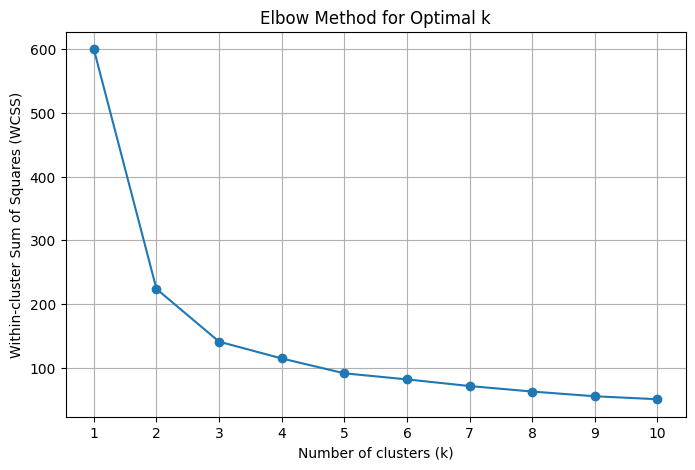

In [5]:
# Find the optimal number of clusters using the Elbow Method

wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k,random_state=42,n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(1,11),wcss,marker='o')

plt.title("Elbow Method for Optimal k")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster Sum of Squares (WCSS)")
plt.xticks(range(1,11))
plt.grid(True)
plt.show()

In [6]:
# Apply K-means clustering
# Here we consider k=3 based on the Elbow Method 
# FOR UNDERSTANDING DON'T WRITE IN PRACTICAL->(Standard for iris dataset is k=3)

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)
df['Cluster']=kmeans.fit_predict(X_scaled)

print("Cluster counts:")
print(df['Cluster'].value_counts().sort_index())

df.head()

Cluster counts:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Cluster
0,1,5.1,3.5,1.4,0.2,Iris-setosa,1
1,2,4.9,3.0,1.4,0.2,Iris-setosa,1
2,3,4.7,3.2,1.3,0.2,Iris-setosa,1
3,4,4.6,3.1,1.5,0.2,Iris-setosa,1
4,5,5.0,3.6,1.4,0.2,Iris-setosa,1


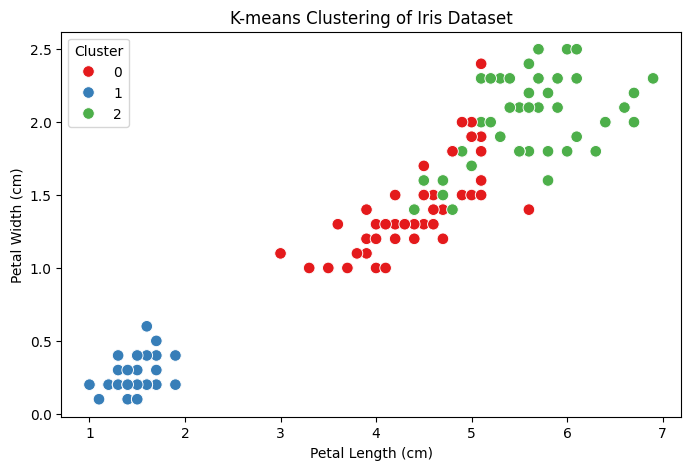

In [7]:
# Visualize the clusters 

plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df,
    x='PetalLengthCm',
    y='PetalWidthCm',
    hue='Cluster',
    palette='Set1',
    s=70
)
plt.title("K-means Clustering of Iris Dataset")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.show()

In [8]:
# Compare clusters with actual species
print("Comparison of predicted clusters with actual species:")
print(pd.crosstab(df['Cluster'], df['Species']))

Comparison of predicted clusters with actual species:
Species  Iris-setosa  Iris-versicolor  Iris-virginica
Cluster                                              
0                  0               39              14
1                 50                0               0
2                  0               11              36


In [9]:
# Final result
print("Final dataset with cluster assignments:")
display(df.head(10))

print("\nTotal number of clusters:", df["Cluster"].nunique())

Final dataset with cluster assignments:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Cluster
0,1,5.1,3.5,1.4,0.2,Iris-setosa,1
1,2,4.9,3.0,1.4,0.2,Iris-setosa,1
2,3,4.7,3.2,1.3,0.2,Iris-setosa,1
3,4,4.6,3.1,1.5,0.2,Iris-setosa,1
4,5,5.0,3.6,1.4,0.2,Iris-setosa,1
5,6,5.4,3.9,1.7,0.4,Iris-setosa,1
6,7,4.6,3.4,1.4,0.3,Iris-setosa,1
7,8,5.0,3.4,1.5,0.2,Iris-setosa,1
8,9,4.4,2.9,1.4,0.2,Iris-setosa,1
9,10,4.9,3.1,1.5,0.1,Iris-setosa,1



Total number of clusters: 3
